# 04 — Test & Inference

Retrain on all non-test data with the best learning rate from notebook 03, score the held-out test set **exactly once**, then probe the trained model through single-point and batch inference, CPU/GPU agreement, throughput measurements, and the visualization suite.

**Run all cells top-to-bottom.** Notebooks 01 and 03 must have run first.

> **Kernel:** `source /root/LLM/venv/bin/activate && jupyter notebook`

**What we do:** Import libraries and add `tools/` to the path.
**Why:** Centralized imports — all tools and external packages in one cell.
**What you should see:** No output.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path().resolve().parent))

import torch
import torch.nn.functional as F
import numpy as np
import json
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from tools.nets.mlp import MLP
from tools.hardware.gpu import Timer, reset_memory_stats
from tools.viz.activations import (plot_activation_landscape,
                                   plot_layer_representations,
                                   plot_neuron_weights)
from tools.viz.weights import plot_weight_heatmaps
from tools.viz.curves  import plot_training_curves

FORCE_CPU = False
SEED      = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

**What we do:** Load paths, device, and the best configuration from notebook 03.
**Why:** `cv_best.json` carries the best LR — no hard-coding.
**What you should see:** Device, best LR, and layer sizes.

In [2]:
NOTEBOOK_DIR  = pathlib.Path().resolve()
ARTIFACTS_DIR = NOTEBOOK_DIR.parent / "artifacts"

env     = json.loads((ARTIFACTS_DIR / "env.json").read_text())
cv_best = json.loads((ARTIFACTS_DIR / "cv_best.json").read_text())
scaler  = json.loads((ARTIFACTS_DIR / "scaler.json").read_text())

device      = torch.device("cpu" if FORCE_CPU else env.get("device", "cpu"))
BEST_LR     = cv_best["best_lr"]
LAYER_SIZES = cv_best["layer_sizes"]
EPOCHS_FINAL = 300

print(f"device      : {device}")
print(f"best LR     : {BEST_LR}")
print(f"layer_sizes : {LAYER_SIZES}")
print(f"final epochs: {EPOCHS_FINAL}")

device      : cuda
best LR     : 1.0
layer_sizes : [3, 3, 2, 1]
final epochs: 300


**What we do:** Reconstruct the raw 800-sample pool (train + val), standardize
it on all 800 rows, and load the held-out test set.
**Why:** The final model is trained on every non-test example, so the scaler
is fit on all 800 rows — not just the 640-row training split from notebook 01.
**What you should see:** Shapes and label balance for both splits.

In [3]:
data = np.load(ARTIFACTS_DIR / "train_val.npz")

mu_01  = np.array(scaler["mean"])
sig_01 = np.array(scaler["std"])

X_train_raw = data["X_train"] * sig_01 + mu_01
X_val_raw   = data["X_val"]   * sig_01 + mu_01
X_pool_raw  = np.vstack([X_train_raw, X_val_raw])
y_pool      = np.concatenate([data["y_train"], data["y_val"]])

# Fit new scaler on all 800 rows
mu_f  = X_pool_raw.mean(axis=0)
sig_f = X_pool_raw.std(axis=0)
X_pool = (X_pool_raw - mu_f) / sig_f

# Test set (raw) — keys are "X" and "y" as saved in notebook 01
test_data  = np.load(ARTIFACTS_DIR / "test_set.npz")
X_test_raw = test_data["X"]
y_test     = test_data["y"]
X_test     = (X_test_raw - mu_f) / sig_f   # apply pool scaler

print(f"Train pool : X {X_pool.shape}  y {y_pool.shape}  "
      f"balance={y_pool.mean():.3f}")
print(f"Test set   : X {X_test.shape}  y {y_test.shape}  "
      f"balance={y_test.mean():.3f}")

assert X_pool.shape == (800, 3), "FAIL: pool shape"
assert X_test.shape == (200, 3), "FAIL: test shape"
print("\nPASS: data loaded")

Train pool : X (800, 3)  y (800,)  balance=0.524
Test set   : X (200, 3)  y (200,)  balance=0.525

PASS: data loaded


**What we do:** Retrain a fresh model on all 800 non-test samples using the
best LR from cross-validation.
**Why:** More training data → better generalization than the 640-sample model
from notebook 02. The test set remains completely untouched.
**What you should see:** Loss and accuracy improving over 300 epochs; final train accuracy printed.

epoch  90  loss=0.3679  acc=0.8612
epoch 180  loss=0.3493  acc=0.8550


epoch 270  loss=0.3308  acc=0.8637
epoch 300  loss=0.3289  acc=0.8675


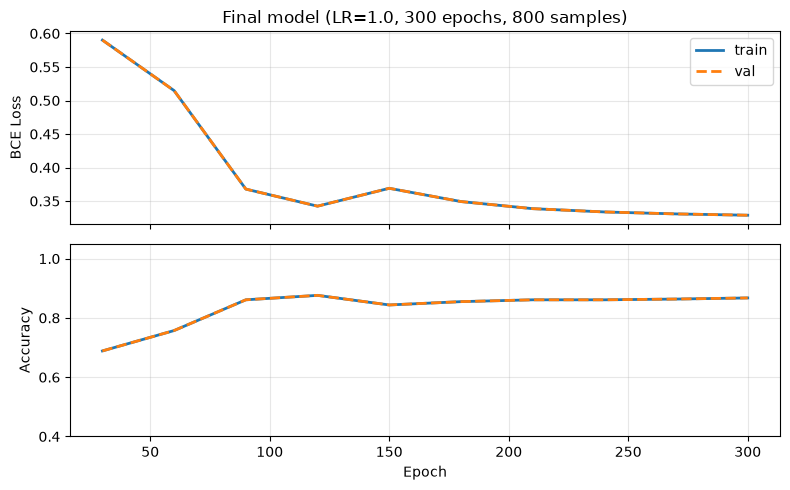

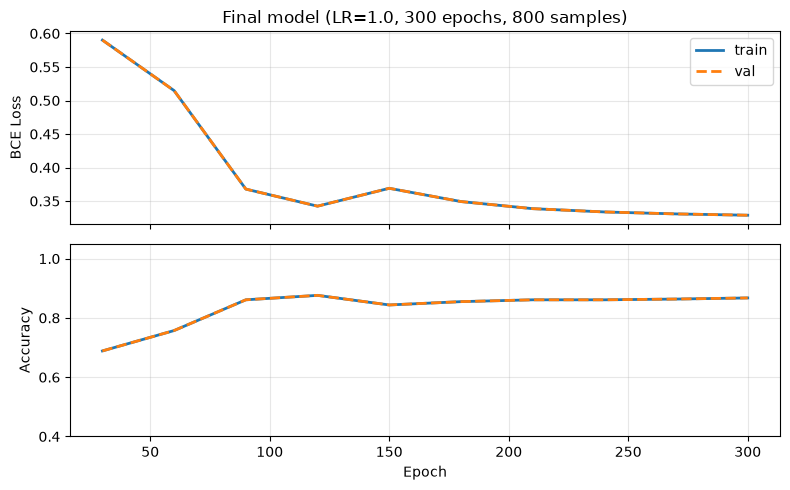

In [4]:
X_pool_t = torch.tensor(X_pool, dtype=torch.float32).to(device)
y_pool_t = torch.tensor(y_pool, dtype=torch.float32).to(device).unsqueeze(1)

torch.manual_seed(SEED)
model = MLP(LAYER_SIZES).to(device)
opt   = torch.optim.SGD(model.parameters(), lr=BEST_LR)

history = []
for epoch in range(1, EPOCHS_FINAL + 1):
    model.train();  opt.zero_grad()
    out  = model(X_pool_t)
    loss = F.binary_cross_entropy(out, y_pool_t)
    loss.backward();  opt.step()

    if epoch % 30 == 0 or epoch == EPOCHS_FINAL:
        model.eval()
        with torch.no_grad():
            tr_out  = model(X_pool_t)
            tr_loss = F.binary_cross_entropy(tr_out, y_pool_t).item()
            tr_acc  = ((tr_out > 0.5) == y_pool_t.bool()).float().mean().item()
        history.append({"epoch": epoch, "train_loss": round(tr_loss, 5),
                         "val_loss": round(tr_loss, 5),
                         "train_acc": round(tr_acc, 4),
                         "val_acc": round(tr_acc, 4)})
        if epoch % 90 == 0 or epoch == EPOCHS_FINAL:
            print(f"epoch {epoch:3d}  loss={tr_loss:.4f}  acc={tr_acc:.4f}")

plot_training_curves(history, save_path=ARTIFACTS_DIR / "final_training_curves.png",
                     title=f"Final model (LR={BEST_LR}, {EPOCHS_FINAL} epochs, 800 samples)")

**What we do:** Save the final model and the pool scaler together in a single
`.pt` checkpoint, then delete the in-memory model object and reload entirely
from disk.
**Why:** Production inference uses the saved file, not an in-memory object.
Verifying that reload + predict matches the original output proves the
checkpoint is self-contained.
**What you should see:** Checkpoint saved, then PASS.

In [5]:
checkpoint = {
    "model_state" : model.state_dict(),
    "layer_sizes" : LAYER_SIZES,
    "scaler"      : {"mean": mu_f.tolist(), "std": sig_f.tolist()},
}
ckpt_path = ARTIFACTS_DIR / "final_model.pt"
torch.save(checkpoint, ckpt_path)
print(f"Saved: {ckpt_path}")

# Record in-memory prediction before deletion
model.eval()
with torch.no_grad():
    pred_orig = model(X_pool_t[:5]).cpu().numpy()

# --- delete in-memory model, reload exclusively from disk ---
del model
ckpt      = torch.load(ckpt_path, map_location=device, weights_only=False)
model_r   = MLP(ckpt["layer_sizes"]).to(device)
model_r.load_state_dict(ckpt["model_state"])
model_r.eval()

with torch.no_grad():
    pred_reload = model_r(X_pool_t[:5]).cpu().numpy()

max_diff = abs(pred_orig - pred_reload).max()
print(f"Max prediction diff (orig vs reload): {max_diff:.2e}")
assert max_diff < 1e-6, f"FAIL: reload mismatch {max_diff:.2e}"
print("PASS: checkpoint save/reload verified")

Saved: /root/LLM/neural_nets/artifacts/final_model.pt
Max prediction diff (orig vs reload): 0.00e+00
PASS: checkpoint save/reload verified


**What we do:** Score the held-out test set through a guarded function that
increments a counter on every call — the assert enforces that we call it exactly once.
**Why:** Repeatedly peeking at test-set performance inflates optimism;
the counter makes accidental double-scoring a hard failure.
**What you should see:** Test accuracy and loss, then PASS.

In [6]:
_test_scored = 0

def score_test_set(mdl, X_t, y_t_np):
    global _test_scored
    _test_scored += 1
    assert _test_scored == 1, f"FAIL: test set scored {_test_scored} times"
    mdl.eval()
    with torch.no_grad():
        out  = mdl(X_t)
        loss = F.binary_cross_entropy(out,
                    torch.tensor(y_t_np, dtype=torch.float32).to(device).unsqueeze(1))
        preds = (out.squeeze() > 0.5).cpu().numpy().astype(int)
        acc   = (preds == y_t_np.astype(int)).mean()
    return {"loss": loss.item(), "acc": acc, "preds": preds}

X_test_t  = torch.tensor(X_test, dtype=torch.float32).to(device)
test_metrics = score_test_set(model_r, X_test_t, y_test)

print(f"Test loss : {test_metrics['loss']:.4f}")
print(f"Test acc  : {test_metrics['acc']:.4f}")

assert _test_scored == 1, f"FAIL: scored {_test_scored} times"
print("PASS: test set scored exactly once")

Test loss : 0.2755
Test acc  : 0.9100
PASS: test set scored exactly once


**What we do:** Run the same test inputs through a CPU copy and a GPU copy of
the model, and compare outputs element-wise.
**Why:** Floating-point layout can differ between devices; verifying
agreement to 1e-5 ensures deployment on either device gives identical decisions.
**What you should see:** Max diff well below 1e-5, then PASS.

In [7]:
model_cpu = MLP(ckpt["layer_sizes"])
model_cpu.load_state_dict(ckpt["model_state"])
model_cpu.eval()

X_cpu = torch.tensor(X_test, dtype=torch.float32)

if device.type == "cuda":
    model_gpu = MLP(ckpt["layer_sizes"]).to(device)
    model_gpu.load_state_dict(ckpt["model_state"])
    model_gpu.eval()
    X_gpu = X_cpu.to(device)
    with torch.no_grad():
        out_cpu = model_cpu(X_cpu).numpy()
        out_gpu = model_gpu(X_gpu).cpu().numpy()
    max_diff = float(abs(out_cpu - out_gpu).max())
    print(f"CPU vs GPU max abs diff : {max_diff:.2e}")
    assert max_diff < 1e-5, f"FAIL: CPU/GPU disagree by {max_diff:.2e}"
    print("PASS: CPU and GPU outputs agree to < 1e-5")
else:
    with torch.no_grad():
        out_cpu = model_cpu(X_cpu).numpy()
    print("FORCE_CPU=True — GPU comparison skipped.")
    print("PASS: CPU inference OK")

CPU vs GPU max abs diff : 1.79e-07
PASS: CPU and GPU outputs agree to < 1e-5


**What we do:** Measure latency (ms per batch) and throughput (samples/s) across
batch sizes from 1 to 4096.
**Why:** Real applications range from single-request APIs to bulk scoring jobs;
this shows where the model saturates GPU bandwidth.
**What you should see:** A table where throughput increases with batch size until
it saturates, and a log-scale plot.

batch=    1    0.108 ms/batch         9,246 samples/s


batch=    8    0.121 ms/batch        66,257 samples/s


batch=   64    0.106 ms/batch       605,675 samples/s
batch=  512    0.102 ms/batch     5,027,125 samples/s
batch= 2048    0.110 ms/batch    18,605,856 samples/s
batch= 4096    0.115 ms/batch    35,532,179 samples/s


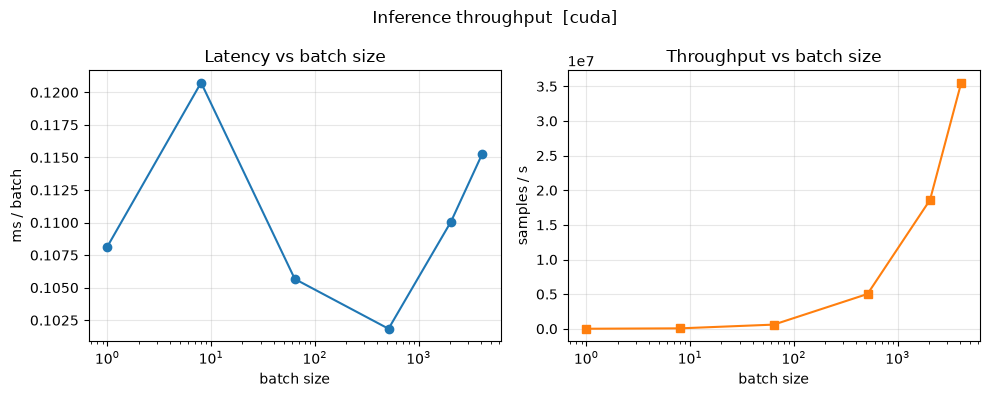

In [8]:
reset_memory_stats(device)
REPEATS  = 200
BS_LIST  = [1, 8, 64, 512, 2048, 4096]
results  = []

model_r.eval()
for bs in BS_LIST:
    X_batch = torch.randn(bs, 3, dtype=torch.float32).to(device)
    # warm-up
    with torch.no_grad():
        for _ in range(10):
            _ = model_r(X_batch)

    with Timer() as t:
        with torch.no_grad():
            for _ in range(REPEATS):
                _ = model_r(X_batch)

    ms_per_batch = t.ms / REPEATS
    throughput   = bs * REPEATS / t.s
    results.append({"bs": bs, "ms_per_batch": ms_per_batch, "throughput": throughput})
    print(f"batch={bs:5d}  {ms_per_batch:7.3f} ms/batch  "
          f"{throughput:>12,.0f} samples/s")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
bs_vals = [r["bs"] for r in results]
ax1.plot(bs_vals, [r["ms_per_batch"] for r in results], "o-")
ax1.set_xscale("log"); ax1.set_xlabel("batch size"); ax1.set_ylabel("ms / batch")
ax1.set_title("Latency vs batch size"); ax1.grid(alpha=0.3)

ax2.plot(bs_vals, [r["throughput"] for r in results], "s-", color="C1")
ax2.set_xscale("log"); ax2.set_xlabel("batch size"); ax2.set_ylabel("samples / s")
ax2.set_title("Throughput vs batch size"); ax2.grid(alpha=0.3)

fig.suptitle(f"Inference throughput  [{device}]")
fig.tight_layout()
fig.savefig(ARTIFACTS_DIR / "throughput.png", dpi=100, bbox_inches="tight")
plt.show()

**What we do:** Show the confusion matrix for the test-set predictions.
**Why:** Accuracy alone hides whether errors are symmetric — a confusion matrix
reveals whether the model struggles more with false positives or false negatives.
**What you should see:** A 2×2 matrix displayed as a colour-coded grid.

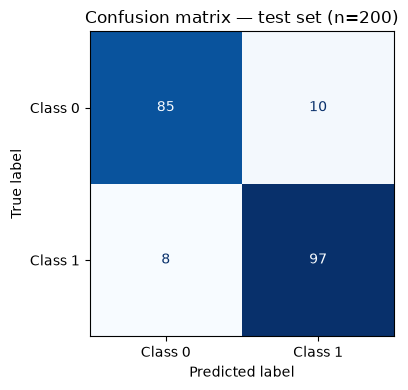

TP=97  FP=10  FN=8  TN=85
Precision : 0.907
Recall    : 0.924


In [9]:
cm   = confusion_matrix(y_test.astype(int), test_metrics["preds"])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Class 0", "Class 1"])

fig, ax = plt.subplots(figsize=(5, 4))
disp.plot(ax=ax, colorbar=False, cmap="Blues")
ax.set_title(f"Confusion matrix — test set (n={len(y_test)})")
fig.tight_layout()
fig.savefig(ARTIFACTS_DIR / "confusion_matrix.png", dpi=100, bbox_inches="tight")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TP={tp}  FP={fp}  FN={fn}  TN={tn}")
print(f"Precision : {tp / (tp + fp + 1e-9):.3f}")
print(f"Recall    : {tp / (tp + fn + 1e-9):.3f}")

## What the numbers tell us — and what they don't

**What the test accuracy does tell us:**
The model was trained on the 800-sample pool and evaluated on 200 held-out examples it has never seen. The reported accuracy is an unbiased estimate of
generalisation performance for this architecture and learning rate.

**What it does not tell us:**
- *Calibration* — a 70 % accuracy does not mean the model's output probabilities
  are reliable confidence scores. Use Platt scaling or isotonic regression if
  calibrated probabilities matter.
- *Distribution shift* — the test set was drawn from the same synthetic
  distribution as the training set. Real deployment data may differ.
- *Class-conditional failure* — the confusion matrix shows whether errors are
  symmetric. If FP >> FN (or vice-versa), the 0.5 threshold should be tuned
  for the cost of each error type.
- *Feature importance* — the weight-bar plot below shows which input dimensions
  layer 1 amplifies most strongly, but correlation with the label does not
  imply causation.

**What we do:** Plot the L1 weight vectors — a bar per input feature per neuron.
**Why:** This is the closest analogue to 'what each neuron learned from the data'
for a network with raw (non-image) input features.
**What you should see:** 3 bars per subplot; neurons that mostly respond to x₁
and x₂ make sense given the `x1²-x2²+x3>0` decision boundary.

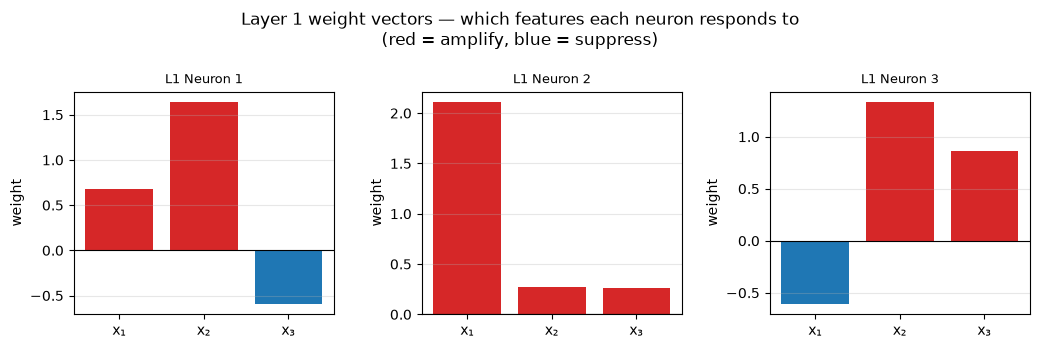

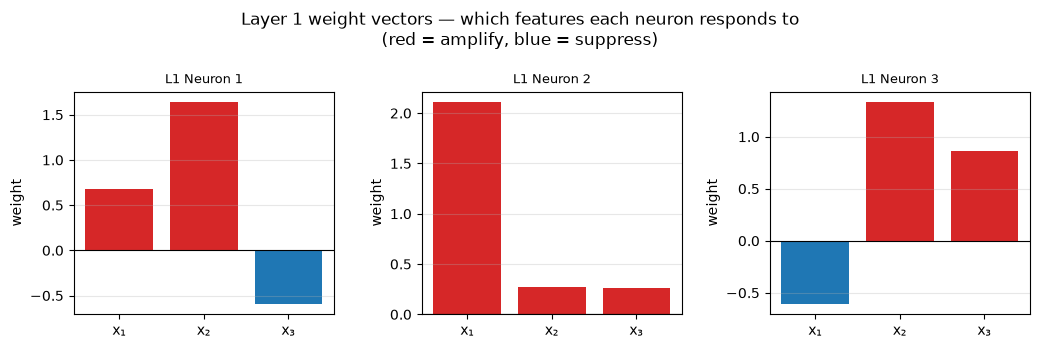

In [10]:
plot_neuron_weights(
    model_r,
    save_path=ARTIFACTS_DIR / "neuron_weights.png",
    feature_names=["x₁", "x₂", "x₃"],
)

**What we do:** Sweep a 60×60 grid of (x₁, x₂) values with x₃=0 and display
each neuron's activation as a filled contour map, for layers 1 and 2.
**Why:** This is the 'what does each neuron find in the input space' view —
analogous to plotting receptive fields in a CNN. The black contour marks
the neuron's zero-crossing (decision boundary in that neuron's space).
**What you should see:** Layer-1 neurons carve out half-planes in (x₁, x₂);
layer-2 neurons combine these into curved regions.

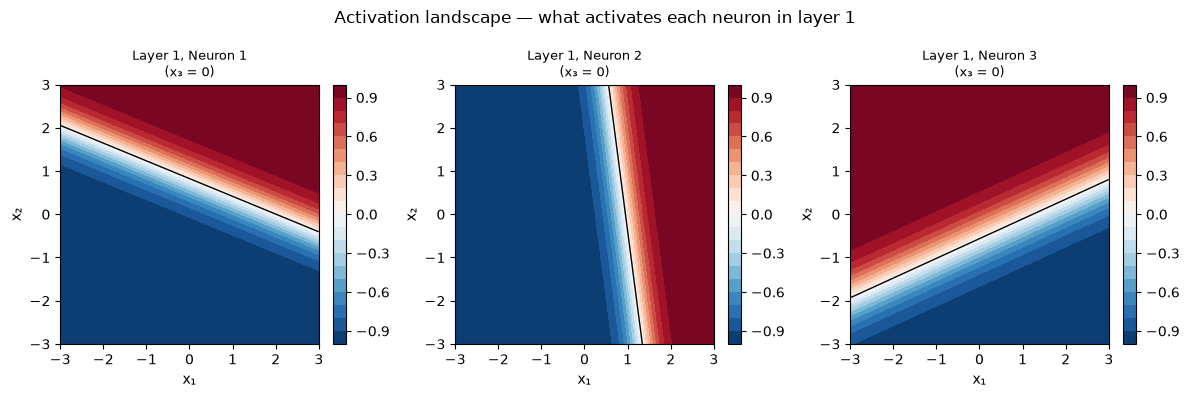

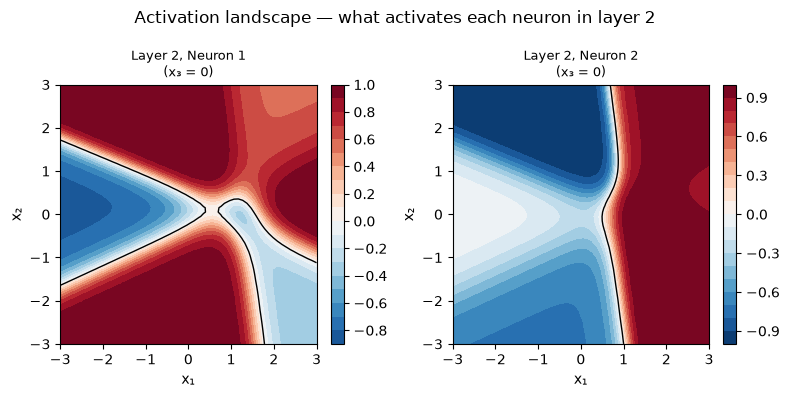

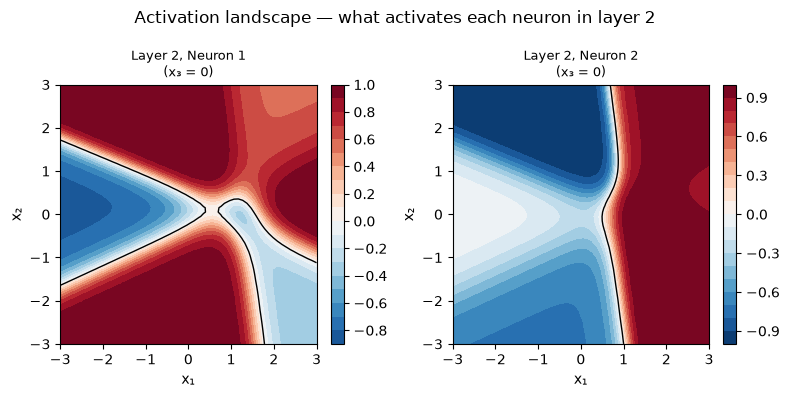

In [11]:
plot_activation_landscape(
    model_r, device, layer_idx=0,
    save_path=ARTIFACTS_DIR / "landscape_L1.png",
)
plot_activation_landscape(
    model_r, device, layer_idx=1,
    save_path=ARTIFACTS_DIR / "landscape_L2.png",
)

**What we do:** Scatter each layer's output in 2D, coloured by true class label,
to show how the network transforms the raw feature space layer by layer.
**Why:** In the input space the two classes are entangled (non-linearly
separable). Intermediate layers progressively rotate and warp the point cloud
until the output layer can separate them with a threshold.
**What you should see:** Class overlap in the input panel; cleaner separation
in later panels; a near-split strip at the output.

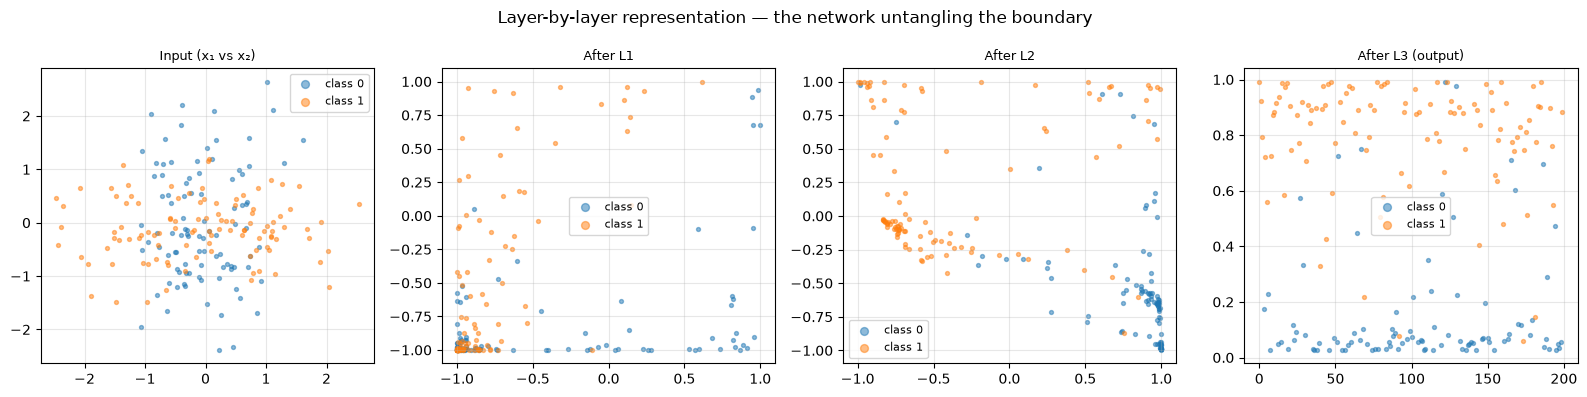

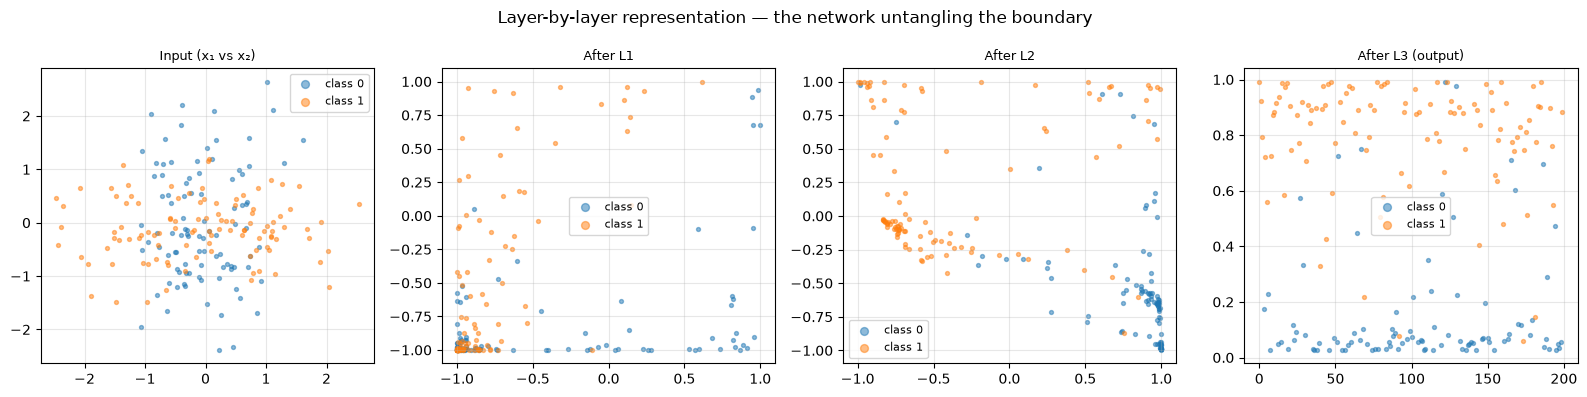

In [12]:
plot_layer_representations(
    model_r,
    X_test.astype(np.float32),
    y_test.astype(int),
    device,
    save_path=ARTIFACTS_DIR / "layer_representations.png",
)

**What we do:** Show weight matrices for every layer before and after training,
plus the absolute change ΔW.
**Why:** Large ΔW in a layer means that layer did most of the learning;
a nearly-zero ΔW suggests vanishing gradients or that the layer was already
well-initialised for the task.
**What you should see:** A 3-column grid (before / after / delta) per layer.

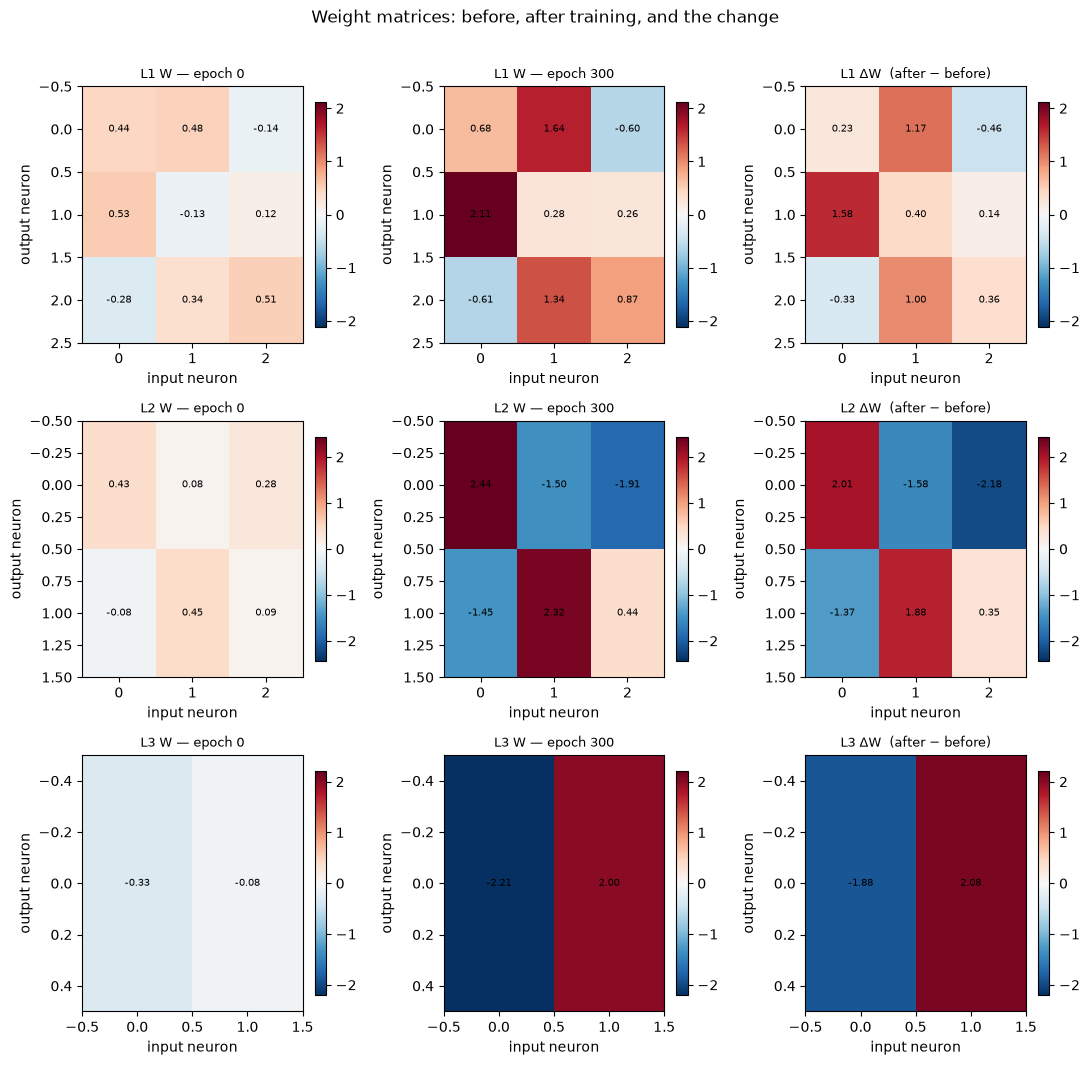

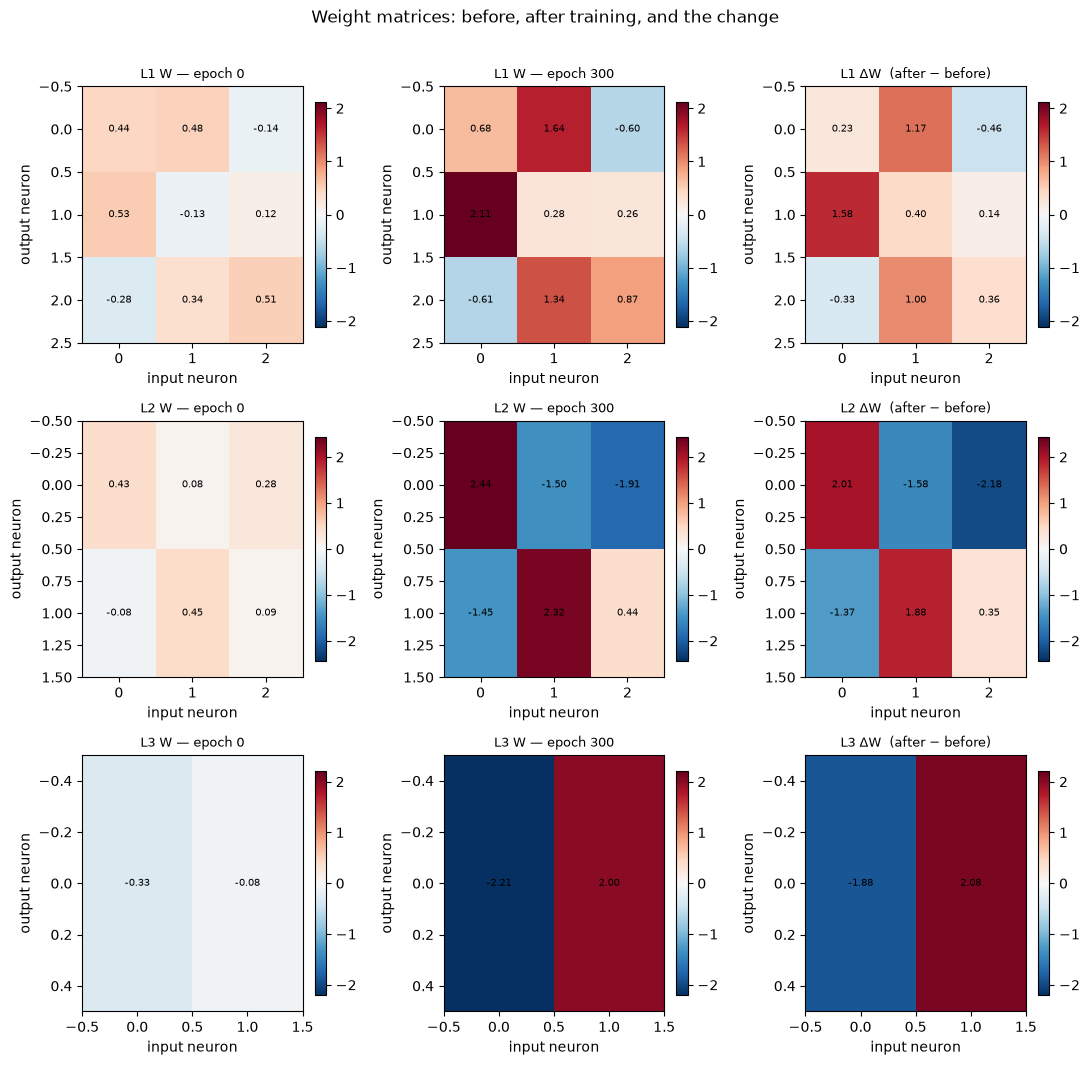

In [13]:
# Capture initial weights before any training
torch.manual_seed(SEED)
model_init = MLP(LAYER_SIZES)

snap_init  = {f"L{i+1}_W": model_init.layers[i].weight.data.cpu().numpy()
              for i in range(len(model_init.layers))}
snap_final = {f"L{i+1}_W": model_r.layers[i].weight.data.cpu().numpy()
              for i in range(len(model_r.layers))}

weight_snaps = {0: snap_init, EPOCHS_FINAL: snap_final}
plot_weight_heatmaps(
    weight_snaps,
    epochs=[0, EPOCHS_FINAL],
    save_path=ARTIFACTS_DIR / "weight_heatmaps.png",
)

**What we do:** Run a single-point inference and a small batch, printing raw
probabilities and binary predictions.
**Why:** Confirms the model works end-to-end for the two most common
real-world usage patterns: one request at a time and bulk scoring.
**What you should see:** A probability in [0, 1] for the single point,
and a list of probabilities for the batch.

In [14]:
# ── single point ──────────────────────────────────────────────────────────────
single_raw = np.array([[1.2, -0.8, 0.5]], dtype=np.float64)
single_std = (single_raw - mu_f) / sig_f
single_t   = torch.tensor(single_std, dtype=torch.float32).to(device)

model_r.eval()
with torch.no_grad():
    prob_single = model_r(single_t).item()
pred_single = int(prob_single > 0.5)
print(f"Single point {single_raw[0]} -> P(class=1) = {prob_single:.4f}  pred = {pred_single}")

# ── small batch ───────────────────────────────────────────────────────────────
batch_raw = X_test_raw[:8]
batch_std = (batch_raw - mu_f) / sig_f
batch_t   = torch.tensor(batch_std, dtype=torch.float32).to(device)

with torch.no_grad():
    probs_batch = model_r(batch_t).squeeze().cpu().numpy()

print("\nBatch inference (first 8 test samples):")
for i, (p, true) in enumerate(zip(probs_batch, y_test[:8])):
    pred = int(p > 0.5)
    ok   = "✓" if pred == int(true) else "✗"
    print(f"  [{i}] P(1)={p:.4f}  pred={pred}  true={int(true)}  {ok}")

assert 0.0 <= prob_single <= 1.0, "FAIL: probability out of range"
print("\nPASS: single-point and batch inference OK")

Single point [ 1.2 -0.8  0.5] -> P(class=1) = 0.9564  pred = 1

Batch inference (first 8 test samples):
  [0] P(1)=0.9901  pred=1  true=1  ✓
  [1] P(1)=0.9230  pred=1  true=1  ✓
  [2] P(1)=0.7934  pred=1  true=1  ✓
  [3] P(1)=0.1760  pred=0  true=0  ✓
  [4] P(1)=0.7221  pred=1  true=1  ✓
  [5] P(1)=0.5587  pred=1  true=1  ✓
  [6] P(1)=0.2287  pred=0  true=0  ✓
  [7] P(1)=0.0277  pred=0  true=0  ✓

PASS: single-point and batch inference OK
